# Post-CCM sensor comparison: old vs CCM-corrected new

Validation report for the calibrated 3×3 colour-correction matrix produced by `calibrate_ccm.py`. The CCM is read from `ccm.json`, applied to the new-sensor images, and the corrected pixels are then compared against the old-sensor target using the same metrics and layout as `sensor_color_comparison.ipynb` so the two notebooks can be read side by side.

**Data:** 4 paired scenes (`0..3.jpg`) under `images/old/` and `images/new/`, 320×240 RGB JPEG.

**Convention in the tables:** `old` = target, `new` = **CCM-corrected** new sensor (what the firmware will produce). Section 9 adds a before / after summary that quantifies what the calibration actually improved.

## Setup

Load the CCM from `ccm.json`, build the transformation matrix in the same column-major convention as the firmware, and apply it to the new-sensor images. `USE_ROUNDED = True` mirrors the values that will actually ship (2-decimal `#define`s); flip to `False` to see the best-case un-rounded calibration. All metric helpers (and `build_ccm` / `apply_ccm`) come from `sensor_metrics.py`, shared with `sensor_color_comparison.ipynb`.

In [1]:
import json
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sensor_metrics import (
    CHANNELS,
    side_by_side,
    load_scenes,
    luminance,
    exposure_stats,
    contrast_stats,
    color_balance_stats,
    hsv_sat_stats,
    quality_stats,
    headline_metrics,
    build_ccm,
    apply_ccm,
)

IMG_ROOT = Path("images")
CCM_JSON = Path("ccm.json")
SCENES = [0, 1, 2, 3]
SENSORS = ("old", "new")  # "new" = CCM-corrected new-sensor pixels
USE_ROUNDED = True  # True = firmware-shipped 2-decimal values; False = raw fit

ccm_data = json.loads(CCM_JSON.read_text())
macros = ccm_data["macros_rounded" if USE_ROUNDED else "macros_raw"]
M = build_ccm(macros)

new_raw = load_scenes(IMG_ROOT / "new", SCENES)
new_corrected = [apply_ccm(img, M) for img in new_raw]
old_imgs = load_scenes(IMG_ROOT / "old", SCENES)
images = {"old": old_imgs, "new": new_corrected}

print("CCM source:", CCM_JSON.resolve())
print("Macro variant:", "rounded (shipped)" if USE_ROUNDED else "raw (full precision)")
print("Matrix M (rows = output channels R, G, B):")
print(M)
print("Row sums (target 1.0):", M.sum(axis=1).round(4).tolist())

CCM source: /home/klymy/projects/researches/people_detection_pg2/investigations/rotated_cam_color_dfiff/ccm.json
Macro variant: rounded (shipped)
Matrix M (rows = output channels R, G, B):
[[ 0.59  0.35  0.06]
 [ 0.22  0.59  0.19]
 [ 0.26 -0.2   0.93]]
Row sums (target 1.0): [1.0, 1.0, 0.99]


## 1. Visual side-by-side and paired difference

**What it shows.** Four columns per scene: `old` (target), `new (raw)` (uncorrected new sensor), `new (CCM)` (corrected new sensor), and `|old - new (CCM)|` (residual diff after correction).

**How to read it.**
- Compare `new (raw)` with `new (CCM)` to see the visual effect of the calibration.
- The residual diff column is the leftover error the matrix could not absorb. A near-uniform low-magnitude residual = clean calibration. Structured bright residuals (vignette, hot-spots, edges) = a 3×3 linear CCM cannot fix it — those require WB gain, vignetting correction, or lens fixes.

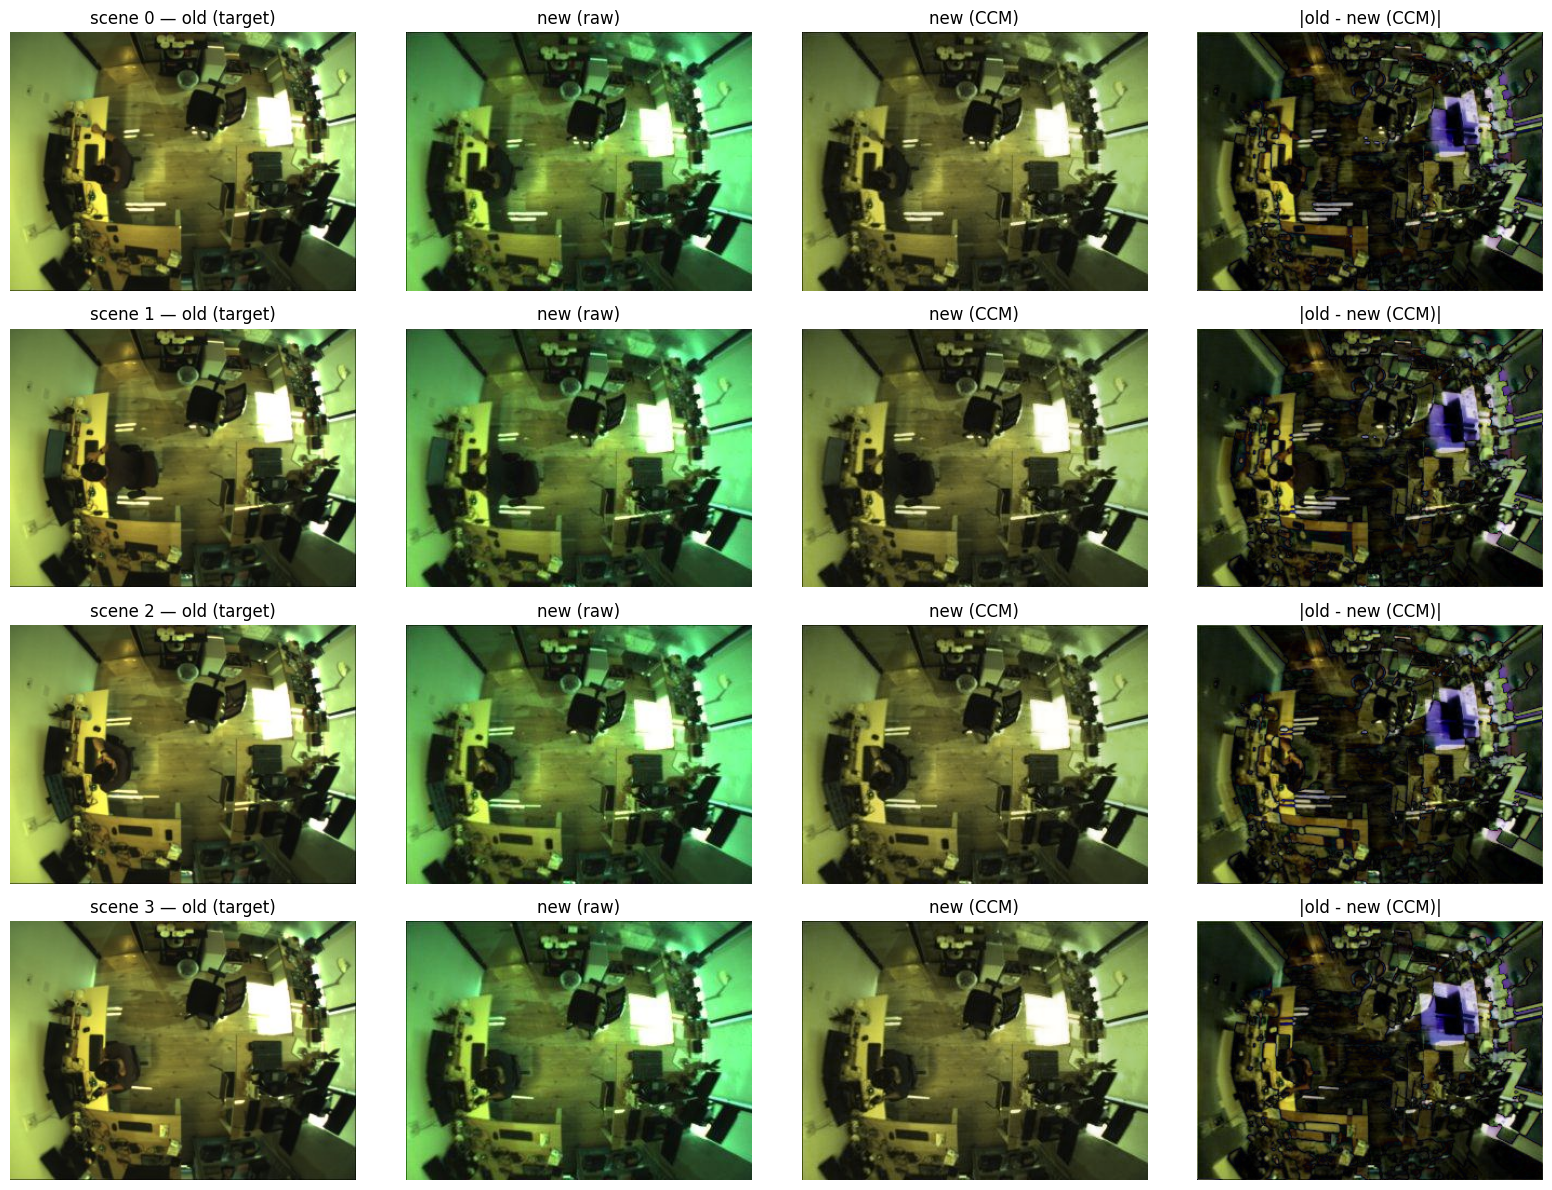

In [2]:
fig, axes = plt.subplots(len(SCENES), 4, figsize=(16, 3 * len(SCENES)))
for i, scene in enumerate(SCENES):
    old = images["old"][i]
    raw = new_raw[i]
    corr = images["new"][i]
    diff = np.abs(old.astype(int) - corr.astype(int)).astype(np.uint8)
    axes[i, 0].imshow(old);  axes[i, 0].set_title(f"scene {scene} \u2014 old (target)")
    axes[i, 1].imshow(raw);  axes[i, 1].set_title("new (raw)")
    axes[i, 2].imshow(corr); axes[i, 2].set_title("new (CCM)")
    axes[i, 3].imshow(diff); axes[i, 3].set_title("|old - new (CCM)|")
    for ax in axes[i]:
        ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Histograms (per-channel R/G/B + luminance)

**What they show.** Distribution of pixel values per channel and overall brightness `Y = 0.299R + 0.587G + 0.114B` for the old (solid) and CCM-corrected new (dashed) sensors.

**How to read it.** A successful CCM brings the corrected channel histograms into alignment with the target — peak positions and overall shape should match. Persistent mismatches indicate residual non-linearities the linear CCM cannot model (gamma, tone-mapping).

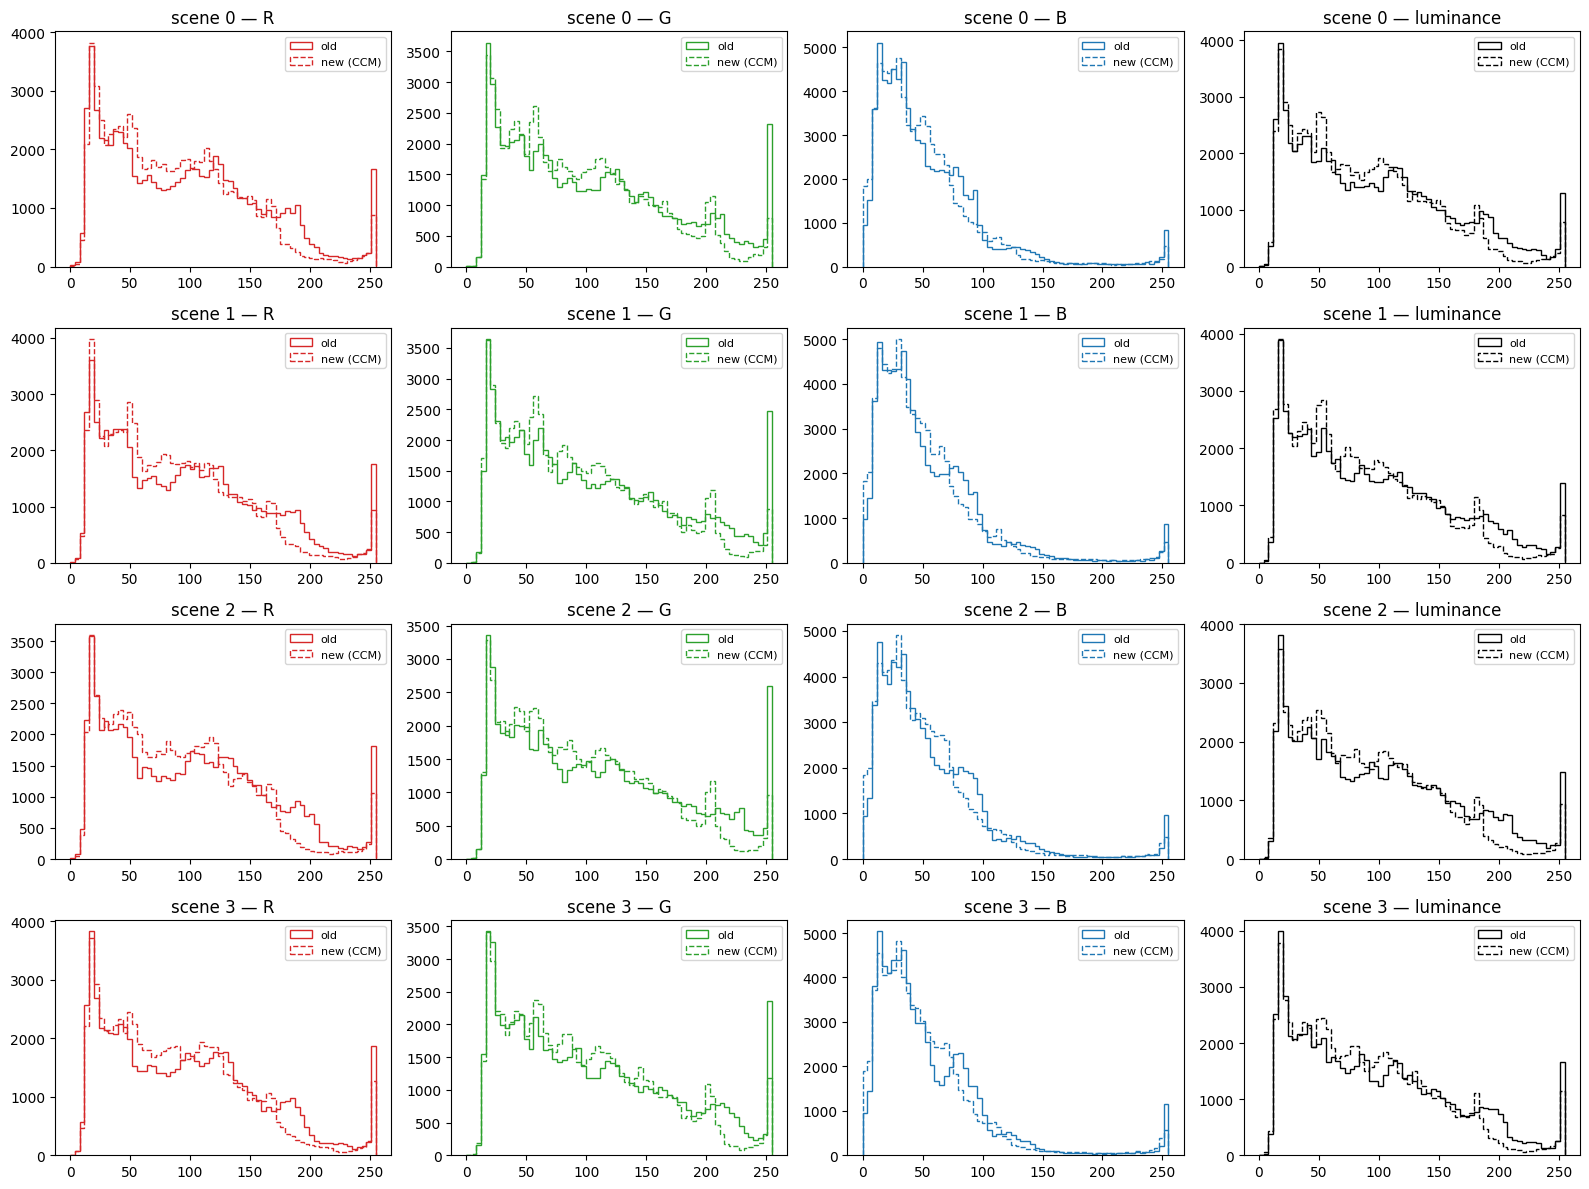

In [3]:
fig, axes = plt.subplots(len(SCENES), 4, figsize=(16, 3 * len(SCENES)))
for i, scene in enumerate(SCENES):
    old, new = images["old"][i], images["new"][i]
    for col, (cname, cidx, color) in enumerate(CHANNELS):
        ax = axes[i, col]
        ax.hist(old[..., cidx].ravel(), bins=64, range=(0, 255),
                histtype="step", color=color, label="old")
        ax.hist(new[..., cidx].ravel(), bins=64, range=(0, 255),
                histtype="step", color=color, linestyle="--", label="new (CCM)")
        ax.set_title(f"scene {scene} \u2014 {cname}")
        ax.legend(fontsize=8)
    ax = axes[i, 3]
    ax.hist(luminance(old).ravel(), bins=64, range=(0, 255),
            histtype="step", color="k", label="old")
    ax.hist(luminance(new).ravel(), bins=64, range=(0, 255),
            histtype="step", color="k", linestyle="--", label="new (CCM)")
    ax.set_title(f"scene {scene} \u2014 luminance")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. Exposure

**Metrics.** `mean_Y`, `shadow_clip_%`, `highlight_clip_%`, `p1`, `p99` — same definitions as the pre-calibration notebook.

**How to read it.** A successful CCM should leave shadow / highlight clipping similar between old and new, and bring `mean_Y` close. A jump in highlight clipping on the corrected new sensor often means the CCM gain is pushing channels above 255 (the firmware will clip them) — look for it. Each row is one scene; old and new (CCM) sit side by side.

In [4]:
side_by_side(exposure_stats, images).round(2)

mean_Y        shadow_clip_%      highlight_clip_%          p1         \
         old    new           old  new              old  new    old    new   
scene                                                                        
0      95.44  86.78           0.0  0.0             0.52  0.0  12.93  12.75   
1      95.11  86.16           0.0  0.0             0.57  0.0  12.92  12.59   
2      99.00  89.34           0.0  0.0             0.53  0.0  13.06  13.19   
3      95.34  88.01           0.0  0.0             0.97  0.0  12.84  12.75   

          p99          
          old     new  
scene                  
0      254.41  251.12  
1      254.41  251.90  
2      254.41  252.73  
3      254.77  253.36

## 4. Contrast

**Metrics.** `std_Y`, `rms_contrast`.

**How to read it.** A CCM with channel-mixing terms can subtly raise or lower contrast. Differences should be small; large drops on the corrected new sensor would be a regression.

In [5]:
side_by_side(contrast_stats, images).round(3)

std_Y         rms_contrast       
          old     new          old    new
scene                                    
0      62.754  55.832        0.658  0.643
1      63.150  56.128        0.664  0.651
2      63.937  56.313        0.646  0.630
3      62.868  56.572        0.659  0.643

## 5. Color balance / white-balance cast

**Metrics.** `mean_R / mean_G / mean_B`, `R/G`, `B/G`, `gray_world_dev`, `Lab_a*`, `Lab_b*`.

**How to read it.** This is the headline section for CCM validation. The green cast on the raw new sensor produced a strongly negative `Lab_a*`. A well-fit CCM should bring `Lab_a*` and `Lab_b*` of the corrected new sensor close to the old-sensor values, and `R/G` and `B/G` ratios into alignment.

In [6]:
side_by_side(color_balance_stats, images).round(2)

mean_R         mean_G        mean_B          R/G         B/G        \
         old    new     old    new    old    new   old   new   old   new   
scene                                                                      
0      95.31  86.34  103.52  93.97  54.11  50.95  0.92  0.92  0.52  0.54   
1      94.75  85.52  103.21  93.33  54.37  50.90  0.92  0.92  0.53  0.55   
2      99.02  88.85  107.31  96.78  56.11  52.34  0.92  0.92  0.52  0.54   
3      95.32  87.50  103.28  95.33  54.44  51.70  0.92  0.92  0.53  0.54   

      gray_world_dev        Lab_a*        Lab_b*         
                 old    new    old    new    old    new  
scene                                                    
0              37.45  32.46 -10.68  -9.95  25.44  22.61  
1              36.91  31.94 -10.71  -9.96  25.12  22.29  
2              38.86  33.52 -10.93 -10.27  26.27  23.28  
3              37.06  32.89 -10.52 -10.11  25.20  22.87

## 6. Saturation and hue

**Metrics.** HSV `mean_S`, `median_S`, and the per-scene hue histogram (overlaid old vs new-CCM).

**How to read it.** A CCM that restores correct color should pull the hue distribution of the corrected new sensor into alignment with the old. A residual peak around hue ≈ 60 (green) after correction means the matrix did not fully remove the cast.

mean_S         median_S       
          old     new      old    new
scene                                
0      125.08  122.86    128.0  124.0
1      124.40  121.94    128.0  124.0
2      125.39  123.64    129.0  125.0
3      124.73  123.54    128.0  125.0

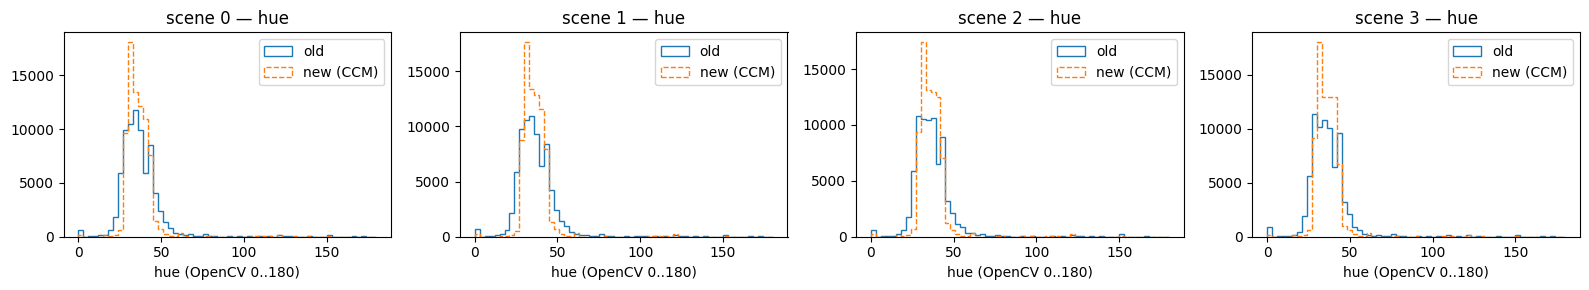

In [7]:
display(side_by_side(hsv_sat_stats, images).round(2))

fig, axes = plt.subplots(1, len(SCENES), figsize=(4 * len(SCENES), 3))
for i, scene in enumerate(SCENES):
    for sensor, ls, label in zip(SENSORS, ("-", "--"), ("old", "new (CCM)")):
        h = cv2.cvtColor(images[sensor][i], cv2.COLOR_RGB2HSV)[..., 0]
        axes[i].hist(h.ravel(), bins=60, range=(0, 180),
                     histtype="step", linestyle=ls, label=label)
    axes[i].set_title(f"scene {scene} \u2014 hue")
    axes[i].set_xlabel("hue (OpenCV 0..180)")
    axes[i].legend()
plt.tight_layout()
plt.show()

## 7. Sharpness and noise

**Metrics.** `sharpness_lap_var`, `noise_hf_std`.

**How to read it.** A 3×3 CCM mixes channels and therefore slightly amplifies both edge response and noise. Small movements here are expected. A large noise jump on the corrected new sensor (vs the raw new sensor) means the matrix has high-magnitude off-diagonal terms — consider raising the row-penalty during recalibration to soften it.

In [8]:
side_by_side(quality_stats, images).round(2)

sharpness_lap_var         noise_hf_std      
                    old     new          old   new
scene                                             
0                794.45  677.87         9.31  8.47
1                822.50  689.63         9.45  8.56
2                845.18  708.45         9.61  8.70
3                743.68  659.73         8.96  8.29

## 8. Paired delta summary (new (CCM) − old)

**What it is.** Headline residuals after correction: one row per scene plus a `mean` row. Same format as the pre-calibration notebook.

**How to read it.** All `Δ` values should be close to zero if the CCM is doing its job. Compare these numbers row-by-row against Section 8 of the pre-calibration notebook to see the per-scene improvement; Section 9 below gives the aggregate before / after comparison.

In [9]:
deltas = []
for i in range(len(SCENES)):
    old_m = headline_metrics(images["old"][i])
    new_m = headline_metrics(images["new"][i])
    deltas.append({"scene": i, **{f"\u0394{k}": new_m[k] - old_m[k] for k in old_m}})

delta_df = pd.DataFrame(deltas).set_index("scene")
delta_df.loc["mean"] = delta_df.mean()
delta_df.round(2)

,ΔL,Δa*,Δb*,ΔR,ΔG,ΔB,Δsharpness,Δnoise,Δsharpness_fft
scene,,,,,,,,,
0,-8.65,0.73,-2.83,-8.97,-9.56,-3.16,-116.58,-0.84,-267.29
1,-8.95,0.75,-2.84,-9.23,-9.87,-3.47,-132.87,-0.89,-283.77
2,-9.65,0.66,-2.98,-10.17,-10.53,-3.78,-136.72,-0.91,-272.64
3,-7.32,0.40,-2.33,-7.83,-7.95,-2.74,-83.95,-0.67,-243.93
mean,-8.65,0.64,-2.75,-9.05,-9.48,-3.29,-117.53,-0.83,-266.91


## 9. Calibration validation: before vs after correction

**What it is.** For each headline metric, the magnitude of the mean delta (new − old) before and after applying the CCM, plus the absolute reduction and percentage reduction. This is the single artifact that answers *"did the calibration help, and by how much?"*.

**How to read it.**
- `|Δ| before` — how far off the raw new sensor was from the old sensor (mean of |delta| across 4 scenes).
- `|Δ| after` — same metric after CCM correction.
- `reduction` — absolute drop in `|Δ|`; positive = improvement.
- `% reduction` — relative improvement; values close to 100% mean the correction effectively removed the bias on that metric.

The color-cast metrics (`a*`, `b*`, raw `R/G/B` channel means) are the ones expected to improve dramatically. `sharpness` and `noise` are expected to be roughly unchanged — large reductions there would be a regression, not a win.

In [10]:
raw_deltas, corr_deltas = [], []
for i in range(len(SCENES)):
    o = headline_metrics(images["old"][i])
    r = headline_metrics(new_raw[i])
    c = headline_metrics(images["new"][i])
    raw_deltas.append({k: r[k] - o[k] for k in o})
    corr_deltas.append({k: c[k] - o[k] for k in o})

raw_abs_mean = pd.DataFrame(raw_deltas).abs().mean()
corr_abs_mean = pd.DataFrame(corr_deltas).abs().mean()

summary = pd.DataFrame({
    "|\u0394| before": raw_abs_mean,
    "|\u0394| after": corr_abs_mean,
    "reduction": raw_abs_mean - corr_abs_mean,
    "% reduction": (1 - corr_abs_mean / raw_abs_mean.replace(0, np.nan)) * 100,
})
summary.round(2)

,|Δ| before,|Δ| after,reduction,% reduction
L,0.88,8.65,-7.77,-885.23
a*,13.04,0.64,12.41,95.12
b*,0.43,2.75,-2.32,-545.69
R,22.35,9.05,13.30,59.51
G,9.86,9.48,0.38,3.83
B,4.49,3.29,1.20,26.73
sharpness,114.94,117.53,-2.59,-2.25
noise,0.79,0.83,-0.04,-5.27
sharpness_fft,256.13,266.91,-10.78,-4.21


## How to use this report

1. **Section 1** — eyeball that the corrected new sensor matches the old visually.
2. **Sections 2–7** — same metrics as the pre-calibration notebook; check that the gap to the old sensor has closed.
3. **Section 8** — per-scene residuals after correction.
4. **Section 9** — the headline before / after table; this is what to paste into the calibration acceptance note.

If any metric in Section 9 shows a *negative* reduction (i.e. the corrected sensor moved *further* from the old), the calibration regressed on that dimension — re-run `calibrate_ccm.py` with a higher `--row-penalty` (to constrain the matrix) or revisit the input scenes.